# Codveda Data Science Internship — Level 1 (Basic)

This notebook covers **Task 2: Data Cleaning & Preprocessing** and **Task 3: Exploratory Data Analysis (EDA)**.

- Task 2 uses the **Boston Housing dataset** (`4) house Prediction Data Set.csv`)
- Task 3 uses the **Iris dataset** (`1) iris.csv`)

## Task 2: Data Cleaning and Preprocessing

**Dataset:** Boston Housing (`4) house Prediction Data Set.csv`) — no header row, whitespace-delimited. Columns follow the classic Boston Housing schema.

**Before running:** Keep the CSV file in the same folder as this notebook, or change the filename in the `pd.read_csv()` cell to its correct path.

**Outlier treatment note:** The notebook flags IQR outliers in continuous predictor columns and caps those values at the IQR boundaries. It preserves all rows and leaves the binary/categorical columns and `MEDV` target unchanged.

In [1]:
import pandas as pd  # Work with tabular data using DataFrames.
import numpy as np  # Use numerical functions when needed.
from sklearn.preprocessing import StandardScaler  # Standardize selected numerical features.

# Define the 14 column names because the Boston Housing file has no header row.
columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD",
           "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]

# Load the whitespace-separated file; header=None tells pandas there is no header row.
# names=columns assigns the column names listed above.
df = pd.read_csv("4) house Prediction Data Set.csv", sep=r"\s+", header=None, names=columns)

# Display the dataset size (number of rows, number of columns).
print("Original shape:", df.shape)

# Show the first five rows so we can inspect the loaded data.
df.head()

Original shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [2]:
# Display the number of missing values in each column.
print("Missing values per column:")
print(df.isnull().sum())
print()

# Count missing cells before cleaning so we can compare before and after.
missing_before = int(df.isnull().sum().sum())

# Fill missing numeric values with their column median.
# The median is less affected by extreme values than the mean.
df = df.fillna(df.median(numeric_only=True))

# Confirm whether the missing-value treatment worked.
missing_after = int(df.isnull().sum().sum())
print(f"Total missing values before filling: {missing_before}")
print(f"Total missing values after filling:  {missing_after}")

Missing values per column:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Total missing values before filling: 0
Total missing values after filling:  0


In [3]:

# Step 1: Import pandas
import pandas as pd

# Step 2: Make a copy so the original dataset remains unchanged
df_clean = df.copy()

# Step 3: Select continuous input features for outlier treatment
# Do NOT include MEDV because it is the house-price target.
# Do NOT include CHAS because it is a binary feature.
# Do NOT include RAD because it is a discrete feature.
columns_to_cap = [
    'CRIM', 'ZN', 'INDUS', 'NOX', 'RM',
    'AGE', 'DIS', 'TAX', 'PTRATIO', 'B', 'LSTAT'
]

# Step 4: Keep only columns that exist in the dataset
columns_to_cap = [
    col for col in columns_to_cap
    if col in df_clean.columns
]

# Step 5: Count the original rows
original_rows = len(df_clean)

# Step 6: Create a dictionary to record how many values are capped
capped_values = {}

# Step 7: Apply the IQR method to cap extreme values
for col in columns_to_cap:

    # Calculate the first and third quartiles
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    # Calculate the Interquartile Range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count values outside the boundaries before capping
    outlier_count = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    # Replace extreme values with the nearest boundary
    # This keeps the rows instead of deleting them
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    # Save the number of values capped in this column
    capped_values[col] = outlier_count

# Step 8: Display the results
print("Original number of rows:", original_rows)
print("Number of rows after outlier treatment:", len(df_clean))
print("Total rows removed:", original_rows - len(df_clean))

print("\nNumber of values capped in each column:")
print(pd.Series(capped_values, name="Values Capped"))

# Step 9: Confirm that MEDV remains unchanged
if 'MEDV' in df.columns:
    print("\nMEDV target unchanged:",
          df_clean['MEDV'].equals(df['MEDV']))

# Step 10: Display the first five rows of the cleaned dataset
display(df_clean.head())

Original number of rows: 506
Number of rows after outlier treatment: 506
Total rows removed: 0

Number of values capped in each column:
CRIM       66
ZN         68
INDUS       0
NOX         0
RM         30
AGE         0
DIS         5
TAX         0
PTRATIO    15
B          77
LSTAT       7
Name: Values Capped, dtype: int64

MEDV target unchanged: True


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [4]:
# 3. Convert the categorical RAD feature into numerical columns.
# CHAS is already binary (0/1), so it can remain as it is.
# RAD is a category code; one-hot encoding avoids treating the codes as a continuous scale.

# Ensure RAD is stored as integer category codes before encoding.
df_clean["RAD"] = df_clean["RAD"].astype(int)

# Create one binary column for each RAD category.
rad_dummies = pd.get_dummies(df_clean["RAD"], prefix="RAD", dtype=int)

# Remove the original RAD column and append the new dummy columns.
df_encoded = pd.concat(
    [df_clean.drop(columns=["RAD"]), rad_dummies],
    axis=1
)

# Display the final feature names after one-hot encoding.
print("Columns after one-hot encoding RAD:")
print(list(df_encoded.columns))
print("Encoded dataset shape:", df_encoded.shape)

Columns after one-hot encoding RAD:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV', 'RAD_1', 'RAD_2', 'RAD_3', 'RAD_4', 'RAD_5', 'RAD_6', 'RAD_7', 'RAD_8', 'RAD_24']
Encoded dataset shape: (506, 22)


In [5]:
# 4. Standardize the continuous input features.
# MEDV is the target variable, so do not scale it as part of the input features.
# CHAS and RAD dummy columns are binary indicators, so leave them as 0/1.

# Build a list of columns that should be standardized.
excluded_cols = ["MEDV", "CHAS"] + list(rad_dummies.columns)
feature_cols = [col for col in df_encoded.columns if col not in excluded_cols]

# Create the scaler that transforms features to approximately mean 0 and standard deviation 1.
scaler = StandardScaler()

# Copy the encoded data so we keep a separate DataFrame for the scaled output.
df_scaled = df_encoded.copy()

# Fit the scaler to these features and transform them.
# For a predictive model, fit the scaler on training data only; this standalone cleaning
# task scales the full dataset for export and exploration.
df_scaled[feature_cols] = scaler.fit_transform(df_encoded[feature_cols])

# Display the means and standard deviations to check the scaling.
print("Scaled feature sample (means should be near 0; standard deviations near 1):")
df_scaled[feature_cols].describe().loc[["mean", "std"]].round(2)

Scaled feature sample (means should be near 0; standard deviations near 1):


,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,TAX,PTRATIO,B,LSTAT
mean,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [6]:
# Choose the output filename. A relative path saves beside the notebook's working directory.
out_path = "house_data_cleaned.csv"

# Save the cleaned, encoded, and scaled dataset without adding an extra index column.
df_scaled.to_csv(out_path, index=False)

# Confirm the output filename and the number of rows and columns saved.
print(f"Saved cleaned dataset to: {out_path}")
print(f"Final dataset shape: {df_scaled.shape}")
print("Note: MEDV remains in its original scale because it is the target variable.")

Saved cleaned dataset to: house_data_cleaned.csv
Final dataset shape: (506, 22)
Note: MEDV remains in its original scale because it is the target variable.


## Task 3: Exploratory Data Analysis (EDA)

**Dataset:** Iris (`1) iris.csv`)

**Before running:** Keep `1) iris.csv` in the same folder as this notebook, or update the path in the loading cell.

In [7]:
# Import plotting libraries for the EDA charts.
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Iris dataset. Update the path if the CSV is stored in another folder.
iris = pd.read_csv("1) iris.csv")

# Show the dataset size and preview the first five rows.
print("Iris dataset shape:", iris.shape)
iris.head()

Iris dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [8]:
# Summary statistics
# Print a heading for the overall summary statistics.
print("Summary statistics:")
# Calculate descriptive statistics such as count, mean, standard deviation, minimum, quartiles, and maximum.
iris.describe()

Summary statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
# Calculate and display the average of each numeric feature for each species.
# Grouping by species makes it easier to compare typical measurements across flower types.
print("Mean measurements grouped by species:")
iris.groupby("species").mean(numeric_only=True).round(2)

Mean measurements grouped by species:


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.42,1.46,0.24
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


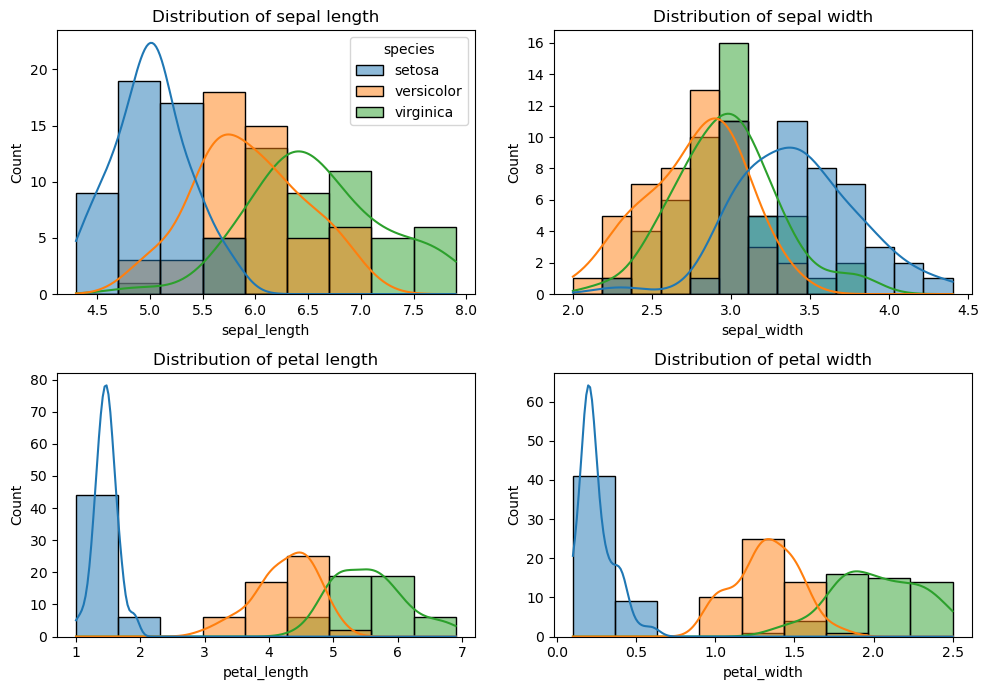

In [10]:
# Create a 2-row by 2-column grid for the four numeric feature histograms.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# List the numeric columns that we want to visualize.
numeric_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# Pair each subplot with a feature column and draw its distribution by species.
for ax, col in zip(axes.ravel(), numeric_cols):
    # hue separates the species; KDE adds a smoothed distribution curve.
    # Show the legend only once to keep the figure uncluttered.
    sns.histplot(
        data=iris, x=col, hue="species", kde=True, ax=ax,
        legend=(col == numeric_cols[0])
    )
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")

# Adjust spacing so subplot titles and labels do not overlap.
plt.tight_layout()
# Render the completed figure.
plt.show()

### Histogram Plot — What Happened?

The histograms show how the values of each Iris feature are distributed across the three species.

- **Sepal length:** The species distributions overlap to some extent, so sepal length alone does not completely separate all three species.
- **Sepal width:** There is also noticeable overlap between species, making it a weaker feature for separating the species.
- **Petal length:** The species form much more distinct distributions. *Setosa* is clearly separated from *versicolor* and *virginica*.
- **Petal width:** This shows a similar pattern to petal length, with *setosa* clearly separated and *versicolor* and *virginica* showing some overlap.
- The **KDE curves** help us see the overall shape of each species' distribution.

**Main takeaway:** The histograms suggest that the petal measurements are more useful for distinguishing the Iris species than the sepal measurements.

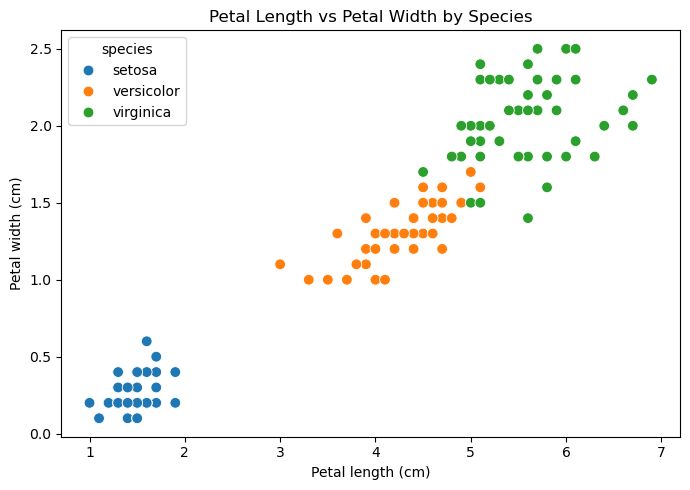

In [11]:
# Compare petal length (x-axis) with petal width (y-axis).
# Each point is one flower; color indicates the flower's species.
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(
    data=iris, x="petal_length", y="petal_width",
    hue="species", s=60, ax=ax
)

# Add descriptive labels and a title so the chart is easy to interpret.
ax.set_title("Petal Length vs Petal Width by Species")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
plt.tight_layout()
plt.show()

### Scatter Plot — What Happened?

The scatter plot compares **petal length** on the x-axis with **petal width** on the y-axis, while the different species are shown separately.

- *Setosa* forms a clearly separated group with much smaller petal length and petal width.
- *Versicolor* and *virginica* are closer to each other and have some overlap.
- The points generally move upward together: flowers with longer petals tend to also have wider petals.
- Because the three groups form relatively distinct clusters, **petal length and petal width are strong features for separating the species**.

**Main takeaway:** This plot visually confirms that petal length and petal width are strong predictors of Iris species, while *versicolor* and *virginica* are harder to distinguish from each other.

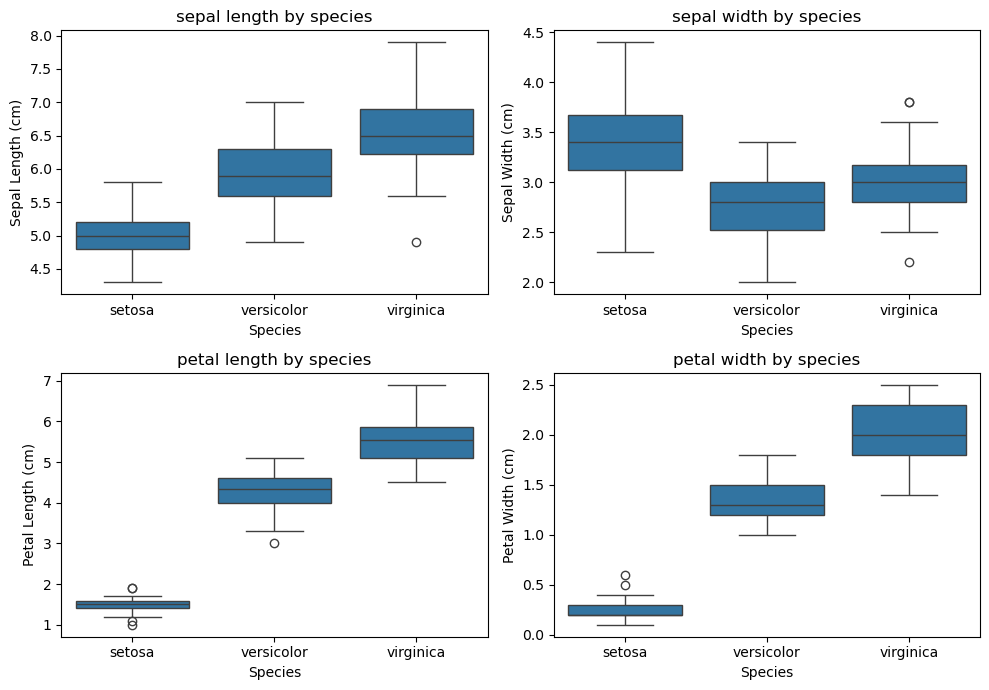

In [12]:
# Create a 2-by-2 grid to compare feature distributions across species.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Draw one box plot for each numeric feature.
for ax, col in zip(axes.ravel(), numeric_cols):
    # A box plot shows the median, middle 50% of values, and potential outliers.
    sns.boxplot(data=iris, x="species", y=col, ax=ax)
    ax.set_title(f"{col.replace('_', ' ')} by species")
    ax.set_xlabel("Species")
    ax.set_ylabel(col.replace("_", " ").title() + " (cm)")

# Improve spacing and display all four plots.
plt.tight_layout()
plt.show()

### Box Plot — What Happened?

The box plots compare the distribution of each numeric feature across the three Iris species.

A box plot helps us see the **median** (middle line), the **spread of the middle 50% of values** (the box), and unusually distant observations that may appear as individual points.

- **Sepal measurements:** The boxes for the species overlap more, showing that these measurements are less clearly separated between species.
- **Petal length and petal width:** The boxes are much more separated, especially for *setosa*, showing that these features differ strongly between species.
- *Versicolor* and *virginica* still show some overlap, particularly compared with the clear separation of *setosa*.
- The plot also helps us inspect whether there are unusually distant observations within each species.

**Main takeaway:** The box plots support the earlier EDA finding that **petal length and petal width provide stronger separation between species than the sepal measurements**.

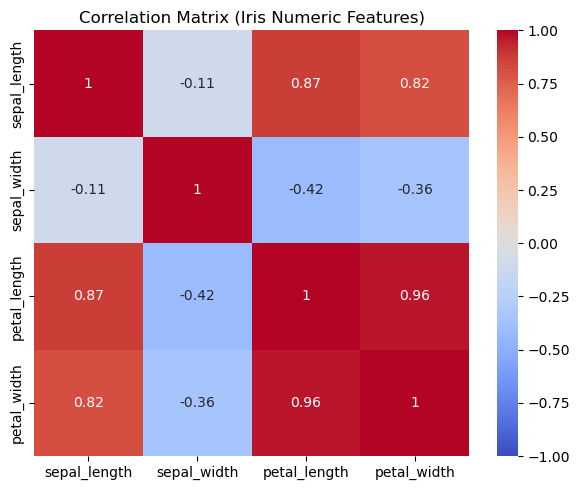

              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00        -0.11          0.87         0.82
sepal_width          -0.11         1.00         -0.42        -0.36
petal_length          0.87        -0.42          1.00         0.96
petal_width           0.82        -0.36          0.96         1.00


In [13]:
# Calculate pairwise correlations between the four numeric Iris measurements.
corr = iris[numeric_cols].corr()

# Create a figure and draw the correlation matrix as a heatmap.
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)

# Add a title and show the chart.
ax.set_title("Correlation Matrix (Iris Numeric Features)")
plt.tight_layout()
plt.show()

# Print the correlation values rounded to two decimal places.
print(corr.round(2))

### Key EDA insights

- **Petal length and petal width are almost perfectly correlated (~0.96)** and together are the strongest separators between species — *setosa* is clearly distinct from *versicolor* and *virginica* on these two features alone.
- **Sepal width has weak/negative correlation with the other features** and is the least useful single feature for separating species.
- **Setosa** is easily linearly separable from the other two species in almost every feature; **versicolor and virginica overlap more**, especially on sepal measurements, meaning a classifier will find those two harder to distinguish (relevant for Level 2 Task 2).
- **No missing values or obvious data-entry outliers were found** in this dataset.